In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data_dir = Path("UCI HAR Dataset")

X_train = pd.read_csv(data_dir / "train" / "X_train.txt", sep=r"\s+", header=None)
X_test = pd.read_csv(data_dir / "test" / "X_test.txt", sep=r"\s+", header=None)

y_train = pd.read_csv(data_dir / "train" / "y_train.txt", header=None).squeeze("columns")
y_test = pd.read_csv(data_dir / "test" / "y_test.txt", header=None).squeeze("columns")

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Test labels:", y_test.shape)

print("\nFirst five rows:")
print(X_train.iloc[:5, :5])

print("\nActivity labels:")
print(y_train.value_counts().sort_index())

Training features: (7352, 561)
Test features: (2947, 561)
Training labels: (7352,)
Test labels: (2947,)

First five rows:
          0         1         2         3         4
0  0.288585 -0.020294 -0.132905 -0.995279 -0.983111
1  0.278419 -0.016411 -0.123520 -0.998245 -0.975300
2  0.279653 -0.019467 -0.113462 -0.995380 -0.967187
3  0.279174 -0.026201 -0.123283 -0.996091 -0.983403
4  0.276629 -0.016570 -0.115362 -0.998139 -0.980817

Activity labels:
0
1    1226
2    1073
3     986
4    1286
5    1374
6    1407
Name: count, dtype: int64


In [3]:
X_train.head()

,0,1,2,3,4,5,6,7,8,9,...,551,552,553,554,555,556,557,558,559,560
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892


In [10]:
from pathlib import Path
import pandas as pd
import numpy as np

data_dir = Path("UCI HAR Dataset")

X_train = pd.read_csv(
    data_dir / "train" / "X_train.txt",
    sep=r"\s+",
    header=None
)

y_train = pd.read_csv(
    data_dir / "train" / "y_train.txt",
    sep=r"\s+",
    header=None
).iloc[:, 0]

# Load feature names
features = pd.read_csv(
    data_dir / "features.txt",
    sep=r"\s+",
    header=None
)

X_train.columns = features.iloc[:, 1].values

print("Dataset shape:", X_train.shape)
print(X_train.head())

Dataset shape: (7352, 561)
   tBodyAcc-mean()-X  tBodyAcc-mean()-Y  tBodyAcc-mean()-Z  tBodyAcc-std()-X  \
0           0.288585          -0.020294          -0.132905         -0.995279   
1           0.278419          -0.016411          -0.123520         -0.998245   
2           0.279653          -0.019467          -0.113462         -0.995380   
3           0.279174          -0.026201          -0.123283         -0.996091   
4           0.276629          -0.016570          -0.115362         -0.998139   

   tBodyAcc-std()-Y  tBodyAcc-std()-Z  tBodyAcc-mad()-X  tBodyAcc-mad()-Y  \
0         -0.983111         -0.913526         -0.995112         -0.983185   
1         -0.975300         -0.960322         -0.998807         -0.974914   
2         -0.967187         -0.978944         -0.996520         -0.963668   
3         -0.983403         -0.990675         -0.997099         -0.982750   
4         -0.980817         -0.990482         -0.998321         -0.979672   

   tBodyAcc-mad()-Z  tBodyAcc

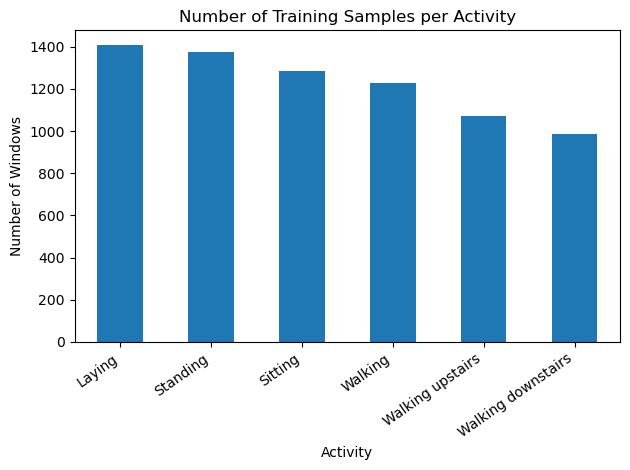

In [5]:
activity_names = {
    1: "Walking",
    2: "Walking upstairs",
    3: "Walking downstairs",
    4: "Sitting",
    5: "Standing",
    6: "Laying"
}

activity_counts = y_train.map(activity_names).value_counts()

activity_counts.plot(kind="bar")
plt.title("Number of Training Samples per Activity")
plt.xlabel("Activity")
plt.ylabel("Number of Windows")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [18]:
raw_file = (
    data_dir / "train" / "Inertial Signals"
    / "body_acc_x_train.txt"
)

raw_acc = pd.read_csv(
    raw_file,
    sep=r"\s+",
    header=None
)

print("Raw signal shape:", raw_acc.shape)

Raw signal shape: (7352, 128)


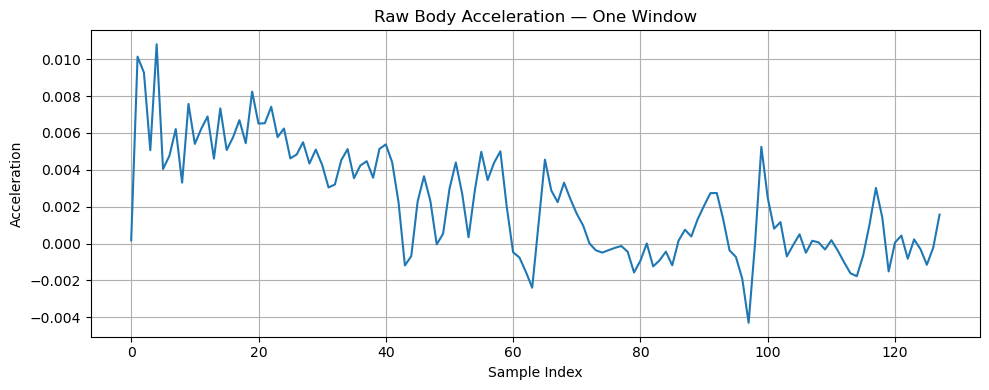

Activity label: Standing


In [19]:
sample_index = 0

plt.figure(figsize=(10, 4))
plt.plot(raw_acc.iloc[sample_index].values)
plt.title("Raw Body Acceleration — One Window")
plt.xlabel("Sample Index")
plt.ylabel("Acceleration")
plt.grid(True)
plt.tight_layout()
plt.show()

print("Activity label:", activity_names[y_train.iloc[sample_index]])

In [11]:
print(X_train.describe().round(3))

       tBodyAcc-mean()-X  tBodyAcc-mean()-Y  tBodyAcc-mean()-Z  \
count           7352.000           7352.000           7352.000   
mean               0.274             -0.018             -0.109   
std                0.070              0.041              0.057   
min               -1.000             -1.000             -1.000   
25%                0.263             -0.025             -0.121   
50%                0.277             -0.017             -0.109   
75%                0.288             -0.011             -0.098   
max                1.000              1.000              1.000   

       tBodyAcc-std()-X  tBodyAcc-std()-Y  tBodyAcc-std()-Z  tBodyAcc-mad()-X  \
count          7352.000          7352.000          7352.000          7352.000   
mean             -0.605            -0.511            -0.605            -0.631   
std               0.449             0.503             0.419             0.424   
min              -1.000            -1.000            -1.000            -1.000   


In [22]:
X_train.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892


In [12]:
selected_features = [
    "tBodyAcc-mean()-X",
    "tBodyAcc-std()-X",
    "tGravityAcc-mean()-X"
]

print(X_train[selected_features].describe().round(3))

       tBodyAcc-mean()-X  tBodyAcc-std()-X  tGravityAcc-mean()-X
count           7352.000          7352.000              7352.000
mean               0.274            -0.605                 0.664
std                0.070             0.449                 0.517
min               -1.000            -1.000                -1.000
25%                0.263            -0.993                 0.805
50%                0.277            -0.946                 0.920
75%                0.288            -0.243                 0.953
max                1.000             1.000                 0.992


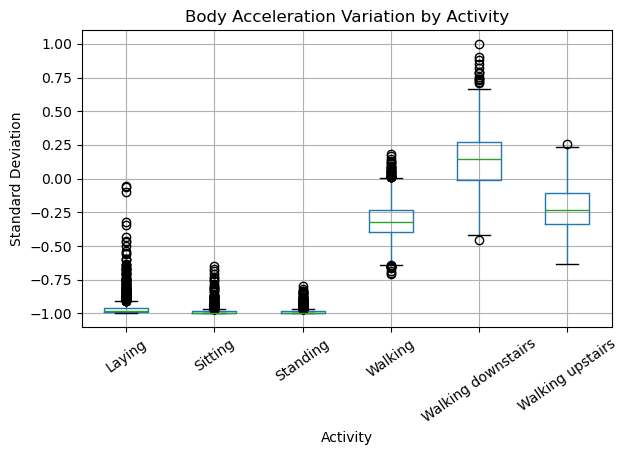

In [13]:
feature_name = "tBodyAcc-std()-X"

plot_df = X_train[[feature_name]].copy()
plot_df["Activity"] = y_train.map(activity_names)

plot_df.boxplot(
    column=feature_name,
    by="Activity",
    rot=35
)

plt.title("Body Acceleration Variation by Activity")
plt.suptitle("")
plt.xlabel("Activity")
plt.ylabel("Standard Deviation")
plt.tight_layout()
plt.show()

In [14]:
activity_means = X_train.groupby(y_train).mean()
activity_means.index = activity_means.index.map(activity_names)

print(activity_means.iloc[:, :10].round(3))

                    tBodyAcc-mean()-X  tBodyAcc-mean()-Y  tBodyAcc-mean()-Z  \
0                                                                             
Walking                         0.276             -0.018             -0.109   
Walking upstairs                0.262             -0.027             -0.120   
Walking downstairs              0.288             -0.016             -0.106   
Sitting                         0.273             -0.012             -0.107   
Standing                        0.279             -0.016             -0.107   
Laying                          0.269             -0.018             -0.107   

                    tBodyAcc-std()-X  tBodyAcc-std()-Y  tBodyAcc-std()-Z  \
0                                                                          
Walking                       -0.313            -0.020            -0.246   
Walking upstairs              -0.221            -0.000            -0.140   
Walking downstairs             0.140             0.079         

In [16]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


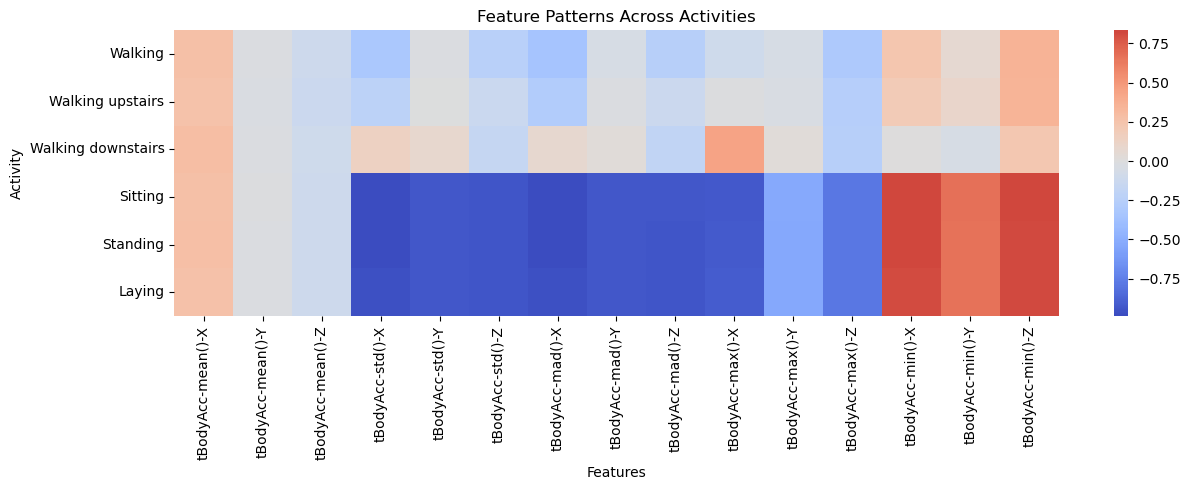

In [17]:
import seaborn as sns

plt.figure(figsize=(13, 5))

sns.heatmap(
    activity_means.iloc[:, :15],
    cmap="coolwarm",
    center=0
)

plt.title("Feature Patterns Across Activities")
plt.xlabel("Features")
plt.ylabel("Activity")
plt.tight_layout()
plt.show()

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train
model.fit(X_train, y_train)

# Predict on unseen test data
y_pred = model.predict(X_test)

# Evaluate
print("Test accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Test accuracy: 0.9256871394638616
              precision    recall  f1-score   support

           1       0.89      0.97      0.93       496
           2       0.88      0.89      0.89       471
           3       0.97      0.86      0.91       420
           4       0.91      0.90      0.90       491
           5       0.91      0.92      0.91       532
           6       1.00      1.00      1.00       537

    accuracy                           0.93      2947
   macro avg       0.93      0.92      0.92      2947
weighted avg       0.93      0.93      0.93      2947



In [20]:

import time
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score
)

# Define the five new models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),

    "SVM (RBF)": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf")
    ),

    "K-Nearest Neighbors": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        random_state=42
    ),

    "Neural Network (MLP)": make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(128, 64),
            activation="relu",
            solver="adam",
            max_iter=300,
            early_stopping=True,
            random_state=42
        )
    )
}

# Store evaluation results
results = []

for name, model in models.items():
    print("\n" + "=" * 60)
    print(f"MODEL: {name}")
    print("=" * 60)

    start_time = time.time()

    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    elapsed = time.time() - start_time

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average="macro")
    weighted_f1 = f1_score(y_test, y_pred, average="weighted")

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Time (seconds)": elapsed
    })

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Training + prediction time: {elapsed:.2f} seconds")

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

# Compare all five models
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("\n\nFINAL MODEL COMPARISON")
print(results_df.round(4).to_string(index=False))



MODEL: Logistic Regression


C:\Users\Tushnik\anaconda3\envs\hack4bengal\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Accuracy: 0.9549
Macro F1: 0.9546
Training + prediction time: 2.19 seconds

Classification Report:
              precision    recall  f1-score   support

           1       0.94      0.99      0.97       496
           2       0.96      0.95      0.95       471
           3       0.99      0.94      0.96       420
           4       0.97      0.88      0.92       491
           5       0.89      0.97      0.93       532
           6       1.00      0.99      1.00       537

    accuracy                           0.95      2947
   macro avg       0.96      0.95      0.95      2947
weighted avg       0.96      0.95      0.95      2947


MODEL: SVM (RBF)


C:\Users\Tushnik\anaconda3\envs\hack4bengal\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Accuracy: 0.9522
Macro F1: 0.9515
Training + prediction time: 6.46 seconds

Classification Report:
              precision    recall  f1-score   support

           1       0.96      0.97      0.97       496
           2       0.93      0.97      0.95       471
           3       0.98      0.92      0.95       420
           4       0.94      0.90      0.92       491
           5       0.92      0.95      0.93       532
           6       1.00      1.00      1.00       537

    accuracy                           0.95      2947
   macro avg       0.95      0.95      0.95      2947
weighted avg       0.95      0.95      0.95      2947


MODEL: K-Nearest Neighbors


C:\Users\Tushnik\anaconda3\envs\hack4bengal\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Accuracy: 0.8802
Macro F1: 0.8766
Training + prediction time: 1.00 seconds

Classification Report:
              precision    recall  f1-score   support

           1       0.82      0.97      0.89       496
           2       0.88      0.90      0.89       471
           3       0.96      0.73      0.83       420
           4       0.88      0.76      0.82       491
           5       0.80      0.93      0.86       532
           6       1.00      0.95      0.97       537

    accuracy                           0.88      2947
   macro avg       0.89      0.87      0.88      2947
weighted avg       0.89      0.88      0.88      2947


MODEL: Gradient Boosting


C:\Users\Tushnik\anaconda3\envs\hack4bengal\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but HistGradientBoostingClassifier was fitted with feature names
  warnings.warn(


Accuracy: 0.9335
Macro F1: 0.9329
Training + prediction time: 29.22 seconds

Classification Report:
              precision    recall  f1-score   support

           1       0.91      0.98      0.95       496
           2       0.93      0.90      0.92       471
           3       0.98      0.92      0.95       420
           4       0.93      0.84      0.88       491
           5       0.87      0.94      0.90       532
           6       1.00      1.00      1.00       537

    accuracy                           0.93      2947
   macro avg       0.94      0.93      0.93      2947
weighted avg       0.94      0.93      0.93      2947


MODEL: Neural Network (MLP)
Accuracy: 0.9444
Macro F1: 0.9442
Training + prediction time: 4.82 seconds

Classification Report:
              precision    recall  f1-score   support

           1       0.95      0.99      0.97       496
           2       0.94      0.95      0.94       471
           3       0.97      0.92      0.95       420
           4

C:\Users\Tushnik\anaconda3\envs\hack4bengal\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(



BENCHMARK: Random_Forest


C:\Users\Tushnik\anaconda3\envs\hack4bengal\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


Training time : 2.375 seconds
Prediction time: 0.0457 seconds
Accuracy      : 0.9257
Macro precision: 0.9270
Macro recall  : 0.9227
Macro F1-score: 0.9240
Weighted F1   : 0.9256

Classification Report:
              precision    recall  f1-score   support

           1       0.89      0.97      0.93       496
           2       0.88      0.89      0.89       471
           3       0.97      0.86      0.91       420
           4       0.91      0.90      0.90       491
           5       0.91      0.92      0.91       532
           6       1.00      1.00      1.00       537

    accuracy                           0.93      2947
   macro avg       0.93      0.92      0.92      2947
weighted avg       0.93      0.93      0.93      2947



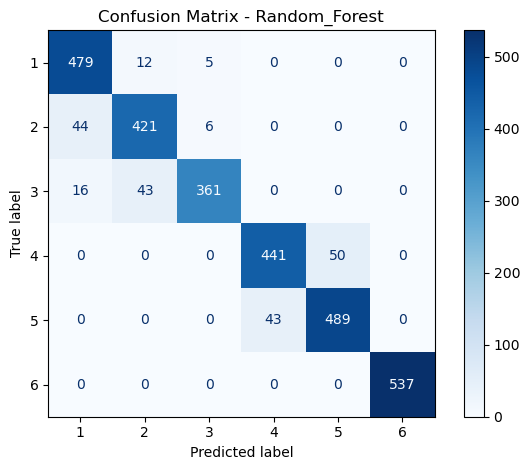

Saved model: models\Random_Forest.joblib

BENCHMARK: Logistic_Regression


C:\Users\Tushnik\anaconda3\envs\hack4bengal\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Training time : 2.061 seconds
Prediction time: 0.0216 seconds
Accuracy      : 0.9549
Macro precision: 0.9577
Macro recall  : 0.9535
Macro F1-score: 0.9546
Weighted F1   : 0.9548

Classification Report:
              precision    recall  f1-score   support

           1       0.94      0.99      0.97       496
           2       0.96      0.95      0.95       471
           3       0.99      0.94      0.96       420
           4       0.97      0.88      0.92       491
           5       0.89      0.97      0.93       532
           6       1.00      0.99      1.00       537

    accuracy                           0.95      2947
   macro avg       0.96      0.95      0.95      2947
weighted avg       0.96      0.95      0.95      2947



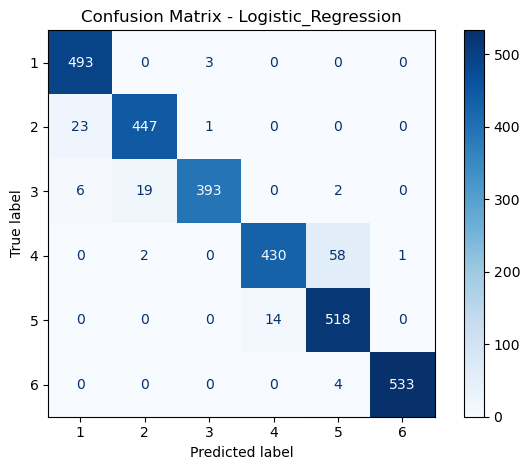

Saved model: models\Logistic_Regression.joblib

BENCHMARK: SVM_RBF


C:\Users\Tushnik\anaconda3\envs\hack4bengal\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Training time : 3.598 seconds
Prediction time: 3.0848 seconds
Accuracy      : 0.9522
Macro precision: 0.9528
Macro recall  : 0.9508
Macro F1-score: 0.9515
Weighted F1   : 0.9521

Classification Report:
              precision    recall  f1-score   support

           1       0.96      0.97      0.97       496
           2       0.93      0.97      0.95       471
           3       0.98      0.92      0.95       420
           4       0.94      0.90      0.92       491
           5       0.92      0.95      0.93       532
           6       1.00      1.00      1.00       537

    accuracy                           0.95      2947
   macro avg       0.95      0.95      0.95      2947
weighted avg       0.95      0.95      0.95      2947



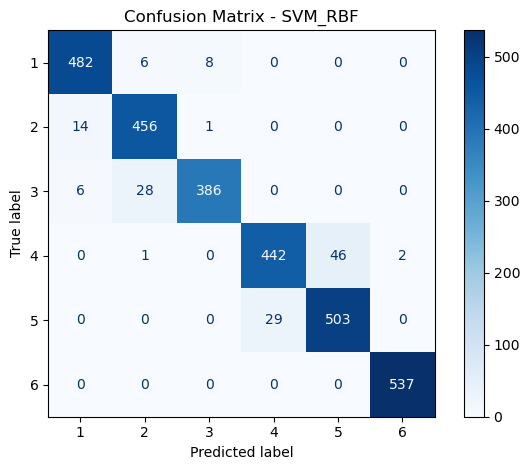

Saved model: models\SVM_RBF.joblib

BENCHMARK: KNN


C:\Users\Tushnik\anaconda3\envs\hack4bengal\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Training time : 0.101 seconds
Prediction time: 0.7623 seconds
Accuracy      : 0.8802
Macro precision: 0.8897
Macro recall  : 0.8746
Macro F1-score: 0.8766
Weighted F1   : 0.8790

Classification Report:
              precision    recall  f1-score   support

           1       0.82      0.97      0.89       496
           2       0.88      0.90      0.89       471
           3       0.96      0.73      0.83       420
           4       0.88      0.76      0.82       491
           5       0.80      0.93      0.86       532
           6       1.00      0.95      0.97       537

    accuracy                           0.88      2947
   macro avg       0.89      0.87      0.88      2947
weighted avg       0.89      0.88      0.88      2947



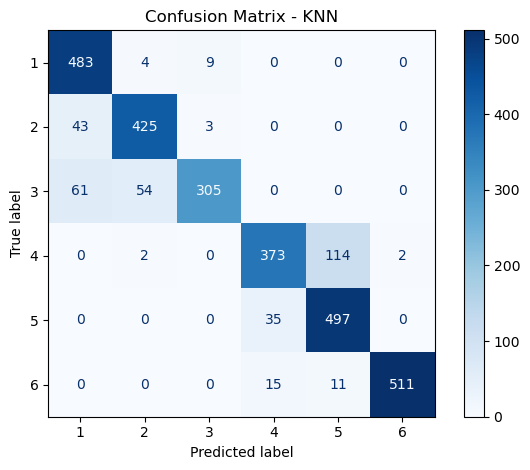

Saved model: models\KNN.joblib

BENCHMARK: Gradient_Boosting


C:\Users\Tushnik\anaconda3\envs\hack4bengal\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but HistGradientBoostingClassifier was fitted with feature names
  warnings.warn(


Training time : 29.706 seconds
Prediction time: 0.0617 seconds
Accuracy      : 0.9335
Macro precision: 0.9361
Macro recall  : 0.9318
Macro F1-score: 0.9329
Weighted F1   : 0.9333

Classification Report:
              precision    recall  f1-score   support

           1       0.91      0.98      0.95       496
           2       0.93      0.90      0.92       471
           3       0.98      0.92      0.95       420
           4       0.93      0.84      0.88       491
           5       0.87      0.94      0.90       532
           6       1.00      1.00      1.00       537

    accuracy                           0.93      2947
   macro avg       0.94      0.93      0.93      2947
weighted avg       0.94      0.93      0.93      2947



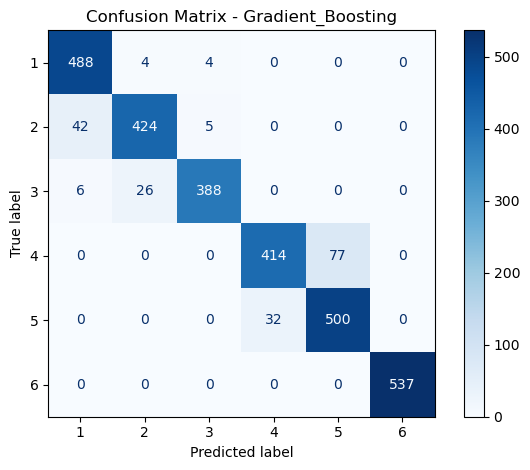

Saved model: models\Gradient_Boosting.joblib

BENCHMARK: Neural_Network_MLP


C:\Users\Tushnik\anaconda3\envs\hack4bengal\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Training time : 5.032 seconds
Prediction time: 0.0278 seconds
Accuracy      : 0.9444
Macro precision: 0.9460
Macro recall  : 0.9432
Macro F1-score: 0.9442
Weighted F1   : 0.9444

Classification Report:
              precision    recall  f1-score   support

           1       0.95      0.99      0.97       496
           2       0.94      0.95      0.94       471
           3       0.97      0.92      0.95       420
           4       0.93      0.89      0.91       491
           5       0.89      0.94      0.91       532
           6       1.00      0.98      0.99       537

    accuracy                           0.94      2947
   macro avg       0.95      0.94      0.94      2947
weighted avg       0.95      0.94      0.94      2947



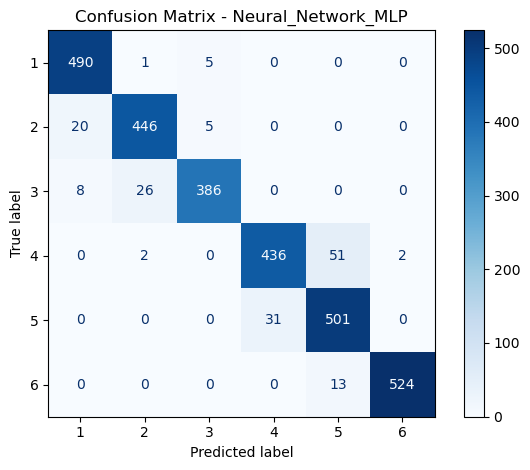

Saved model: models\Neural_Network_MLP.joblib

FINAL BENCHMARK COMPARISON
              Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1  Training Time (s)  Prediction Time (s)
Logistic_Regression    0.9549           0.9577        0.9535    0.9546       0.9548             2.0608               0.0216
            SVM_RBF    0.9522           0.9528        0.9508    0.9515       0.9521             3.5980               3.0848
 Neural_Network_MLP    0.9444           0.9460        0.9432    0.9442       0.9444             5.0319               0.0278
  Gradient_Boosting    0.9335           0.9361        0.9318    0.9329       0.9333            29.7057               0.0617
      Random_Forest    0.9257           0.9270        0.9227    0.9240       0.9256             2.3749               0.0457
                KNN    0.8802           0.8897        0.8746    0.8766       0.8790             0.1009               0.7623

Benchmark results saved to: models\benchmark_results.csv


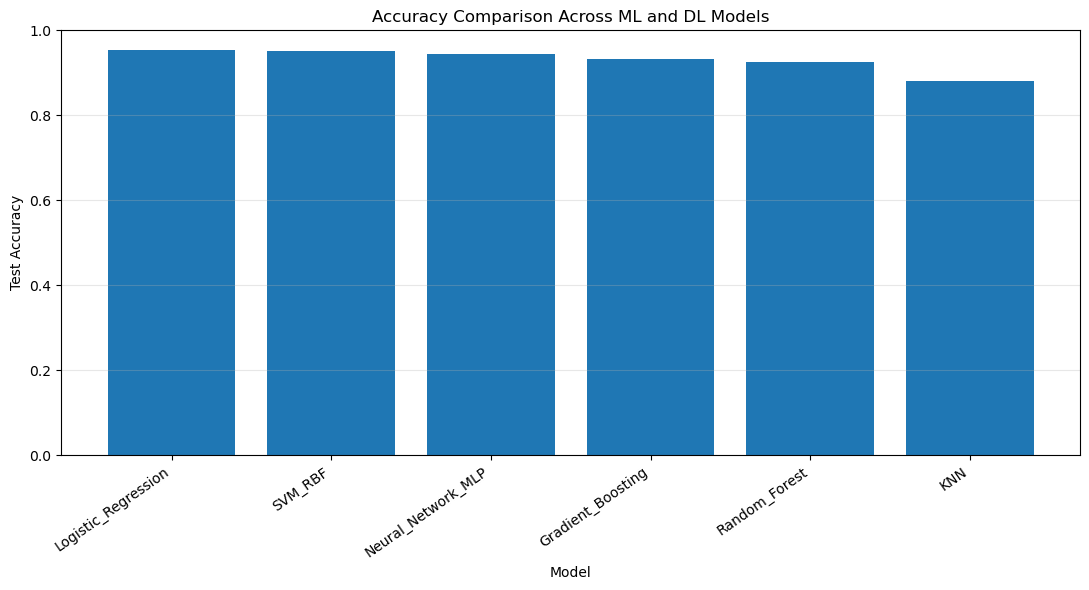


Saved files:
models\benchmark_results.csv
models\Gradient_Boosting.joblib
models\KNN.joblib
models\Logistic_Regression.joblib
models\Neural_Network_MLP.joblib
models\Random_Forest.joblib
models\SVM_RBF.joblib


In [21]:

# If needed:
# %pip install scikit-learn pandas matplotlib joblib

import time
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# --------------------------------------------------
# 1. Create the model-saving directory
# --------------------------------------------------

models_dir = Path("models")
models_dir.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. Define all six models
# --------------------------------------------------

models = {
    "Random_Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Logistic_Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),

    "SVM_RBF": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf")
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Gradient_Boosting": HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        random_state=42
    ),

    "Neural_Network_MLP": make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(128, 64),
            activation="relu",
            solver="adam",
            max_iter=300,
            early_stopping=True,
            random_state=42
        )
    )
}

# --------------------------------------------------
# 3. Train, benchmark, display and save each model
# --------------------------------------------------

results = []

for name, model in models.items():

    print("\n" + "=" * 70)
    print(f"BENCHMARK: {name}")
    print("=" * 70)

    start_time = time.perf_counter()

    # Train the model
    model.fit(X_train, y_train)
    training_time = time.perf_counter() - start_time

    # Measure prediction time separately
    start_time = time.perf_counter()
    y_pred = model.predict(X_test)
    prediction_time = time.perf_counter() - start_time

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    macro_f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    weighted_f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    # Print the benchmark results
    print(f"Training time : {training_time:.3f} seconds")
    print(f"Prediction time: {prediction_time:.4f} seconds")
    print(f"Accuracy      : {accuracy:.4f}")
    print(f"Macro precision: {precision:.4f}")
    print(f"Macro recall  : {recall:.4f}")
    print(f"Macro F1-score: {macro_f1:.4f}")
    print(f"Weighted F1   : {weighted_f1:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

    # Display a confusion matrix for this model
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        cmap="Blues",
        values_format="d"
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

    # Save the fitted model, including its scaler if applicable
    model_path = models_dir / f"{name}.joblib"
    joblib.dump(model, model_path)

    print(f"Saved model: {model_path}")

    # Store metrics for the final comparison
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time
    })

# --------------------------------------------------
# 4. Display the final benchmark comparison
# --------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 100)
print("FINAL BENCHMARK COMPARISON")
print("=" * 100)
print(results_df.round(4).to_string(index=False))

# Save benchmark results
results_df.to_csv(
    models_dir / "benchmark_results.csv",
    index=False
)

print(f"\nBenchmark results saved to: {models_dir / 'benchmark_results.csv'}")

# --------------------------------------------------
# 5. Plot model accuracy comparison
# --------------------------------------------------

plt.figure(figsize=(11, 6))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("Accuracy Comparison Across ML and DL Models")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1.0)
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. Confirm saved files
# --------------------------------------------------

print("\nSaved files:")
for file in sorted(models_dir.iterdir()):
    print(file)


In [ ]:
import joblib

model = joblib.load("models/Neural_Network_MLP.joblib")

predictions = model.predict(X_test)

print(predictions[:10])
#For Loading using Joblib incase I forgot.